# 03 — From counting to a network: one-hot inputs and the weight matrix `W`

**Chapter 1** · suggested time: 20 min · CPU only · [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/en/chapter_1/03_one_hot_and_weights.ipynb)

![Chapter roadmap](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_1/figures/00_roadmap.png)

## 1. Why build a network when we already have `P`?

Our first model works: it counts the transitions and gets an NLL of 2.45. **For a simple bigram, counting is even the most direct method.** We do not claim the network will do better.

**The new challenge:** get the *same kind* of table **without counting**. We start from a matrix of random numbers, and correct it using gradients.

| Counting model (notebooks 01–02) | Neural model (notebooks 03–06) |
|:---|:---|
| We count the transitions in `N`. | We draw random numbers in `W`. |
| We divide each row of `N` by its sum. | We turn each row of `W` into probabilities (softmax, notebook 04). |
| One row = "what follows this character?" | One row = "what scores to give the next characters?" |
| The probabilities come directly from the data. | The probabilities come from weights adjusted by the loss. |

**Why bother?** Counting does not scale. With 3 characters of context, we would already need 27³ × 27 ≈ 530,000 cells, almost all empty. With a network, we will be able to **enlarge the context without counting everything**: this is exactly what the Transformer of chapter 2 will do. The bigram is the simplest case for understanding the mechanics, because we know the right answer (the table `P`).

**Common thread:** `current character → one-hot → row of W → scores → probabilities → loss → update of W`. This notebook covers the first three arrows.

In [1]:
# On Google Colab: fetch the course repository (corpus + shared modules such as bigram.py).
# Locally, this cell does nothing.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("bigram.py"):
    if not os.path.exists("ai-masterclass"):
        !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/en/chapter_1

In [2]:
# Setup: imports and the chapter's small shared module
import math
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

import bigram  # file bigram.py, next to this notebook
from bigram import SEED, plot_char_matrix

words = bigram.load_names()
chars, stoi, itos = bigram.build_vocabulary(words)
print(f"{len(words):,} names · vocabulary of {len(stoi)} symbols · PyTorch {torch.__version__}")

N = bigram.count_bigrams(words, stoi)
P = N.float() / N.sum(dim=1, keepdim=True)

32,033 names · vocabulary of 27 symbols · PyTorch 2.15.0+cu132


## 2. Inputs and correct answers

A network is not trained directly on the string `"emma"`. For **each transition**, it receives an **input** and an **expected answer**. A 4-letter name thus hides **five exercises**:

| exercise | given character `x` | expected answer `y` | indices `(x, y)` |
|---:|:---:|:---:|:---:|
| 1 | `.` | `e` | `(0, 5)` |
| 2 | `e` | `m` | `(5, 13)` |
| 3 | `m` | `m` | `(13, 13)` |
| 4 | `m` | `a` | `(13, 1)` |
| 5 | `a` | `.` | `(1, 0)` |

- `xs` contains the **inputs**: what the network **sees**;
- `ys` contains the **correct answers**: what we **ask it to predict**. They are used to compute the loss, as in notebook 02.

**Question for the class:** why does `m` appear twice in `xs`? Because two bigrams of `emma` start with `m`: `m→m` and `m→a`. **The same context can have several correct answers.** No bigram model can be 100% right on both.

In [3]:
sequence = ["."] + list("emma") + ["."]
transitions = list(zip(sequence, sequence[1:]))

xs_small = torch.tensor([stoi[ch1] for ch1, ch2 in transitions], dtype=torch.long)
ys_small = torch.tensor([stoi[ch2] for ch1, ch2 in transitions], dtype=torch.long)

for t, ((ch1, ch2), x, y) in enumerate(zip(transitions, xs_small, ys_small), start=1):
    print(f"Example {t}: input '{ch1}' (x={x.item():2d}) → true answer '{ch2}' (y={y.item():2d})")
print("\nxs_small =", xs_small.tolist(), "| shape", tuple(xs_small.shape))
print("ys_small =", ys_small.tolist(), "| shape", tuple(ys_small.shape))

Example 1: input '.' (x= 0) → true answer 'e' (y= 5)
Example 2: input 'e' (x= 5) → true answer 'm' (y=13)
Example 3: input 'm' (x=13) → true answer 'm' (y=13)
Example 4: input 'm' (x=13) → true answer 'a' (y= 1)
Example 5: input 'a' (x= 1) → true answer '.' (y= 0)

xs_small = [0, 5, 13, 13, 1] | shape (5,)
ys_small = [5, 13, 13, 1, 0] | shape (5,)


## 3. Why not give the index `13` directly to the network?

The number `13` that represents `m` is an **arbitrary label**. If we fed it as is into a multiplication, the network would "believe" that `m` is worth 13 times `a`, or that `l` (12) is close to `m` because their numbers are neighbors. That is wrong.

Simple solution: **one slot per symbol**.
- a vector of **27 slots**, one per possible character;
- **26 zeros** and **a single `1`**, in the slot of the observed character.

This is **one-hot** encoding ("a single slot switched on"). It says nothing about the meaning of the letters: it only says **which one is present**.

> **Shape:** 5 examples, and for each a vector of 27 values. So `xs_small` of shape `(5,)` becomes `F.one_hot(xs_small)` of shape `(5, 27)`.

Shape of the indices : (5,)
Shape of the one-hots: (5, 27)
Slot on, per row     : [0, 5, 13, 13, 1]
Number of 1s per row : [1.0, 1.0, 1.0, 1.0, 1.0]


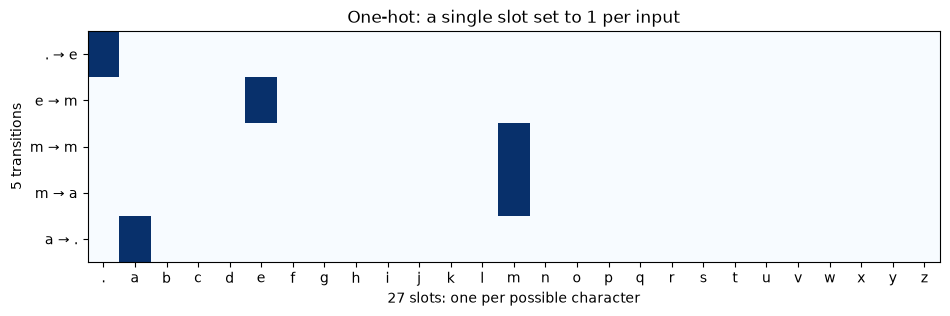

In [4]:
# F.one_hot returns integers; .float() is needed for the multiplication by W (real numbers).
xenc_small = F.one_hot(xs_small, num_classes=27).float()

print("Shape of the indices :", tuple(xs_small.shape))
print("Shape of the one-hots:", tuple(xenc_small.shape))
print("Slot on, per row     :", xenc_small.argmax(dim=1).tolist())
print("Number of 1s per row :", xenc_small.sum(dim=1).tolist())

fig, ax = plt.subplots(figsize=(11, 3))
ax.imshow(xenc_small.numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(27), [itos[i] for i in range(27)])
ax.set_yticks(range(5), [f"{a} → {b}" for a, b in transitions])
ax.set_xlabel("27 slots: one per possible character"); ax.set_ylabel("5 transitions")
ax.set_title("One-hot: a single slot set to 1 per input")
plt.show()

## 4. What does the multiplication `one-hot @ W` really do?

![One-hot times W](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_1/figures/03_one_hot_selection.png)

Let's not start right away with a 27 × 27 matrix. Take **3 characters** (`a`, `b`, `c`) and a matrix of **scores** (not probabilities yet). Each row corresponds to the *current* character, each column to the *next* character:

$$
W_{\mathrm{mini}}=
\begin{bmatrix} 2 & 1 & 0\\ 4 & 5 & 6\\ 7 & 8 & 9 \end{bmatrix},
\qquad x_b=\begin{bmatrix}0 & 1 & 0\end{bmatrix}.
$$

Let's compute column by column:

$$
x_b W_{\mathrm{mini}}
= \big[\,0\cdot 2 + 1\cdot 4 + 0\cdot 7,\;\; 0\cdot 1 + 1\cdot 5 + 0\cdot 8,\;\; 0\cdot 0 + 1\cdot 6 + 0\cdot 9\,\big]
= \begin{bmatrix} 4 & 5 & 6 \end{bmatrix}.
$$

The `0`s cancel the rows `a` and `c`, the `1` keeps **the whole row `b`**. This product is a **row selection**, not a mixture.

**Before running:** is `[4, 5, 6]` a probability distribution? No: these numbers do not sum to 1. They are **scores**. Turning them into probabilities is the subject of notebook 04.

In [5]:
W_mini = torch.tensor([
    [2., 1., 0.],  # scores if the current character is 'a'
    [4., 5., 6.],  # scores if the current character is 'b'
    [7., 8., 9.],  # scores if the current character is 'c'
])
x_b = torch.tensor([0., 1., 0.])

result = x_b @ W_mini
print("x_b @ W_mini =", result.tolist())
print("row b        =", W_mini[1].tolist())
assert torch.equal(result, W_mini[1])     # an algebraic identity, not a coincidence
print("With [1,0,0]:", (torch.tensor([1., 0., 0.]) @ W_mini).tolist(), "= row a")

x_b @ W_mini = [4.0, 5.0, 6.0]
row b        = [4.0, 5.0, 6.0]
With [1,0,0]: [2.0, 1.0, 0.0] = row a


## 5. The same thing on the five bigrams of `emma`

Back to **27 characters**. We draw a matrix `W` of shape `(27, 27)` at random, from a standard normal distribution (`torch.randn`). For now, it only serves to **observe the mechanism**. No optimization happens here.

$$
\underbrace{X_{\text{one-hot}}}_{(5,\,27)}\;@\;\underbrace{W}_{(27,\,27)}\;=\;\underbrace{\text{scores}}_{(5,\,27)}
$$

**Reading the three dimensions:**
- **5**: we predict the next character for five transitions;
- **27 in the middle**: the 27 slots of the one-hot correspond to the 27 rows of `W`. These two dimensions **must** be equal;
- **27 at the output**: for each input, we get 27 scores, one per possible next character.

In `emma`, examples 3 and 4 have the **same input** (`m`). So they select **the same row of `W`** and receive **the same scores**, even though their correct answers differ. This is the fundamental limit of the bigram: it does not know what came before.

xenc_small: (5, 27)  @  W: (27, 27)  =  scores: (5, 27)
one-hot @ W == W[xs_small]? True
Examples 3 and 4: same input 'm'? True | same 27 scores? True
Number of parameters in W: 729 = as many as there are cells in N


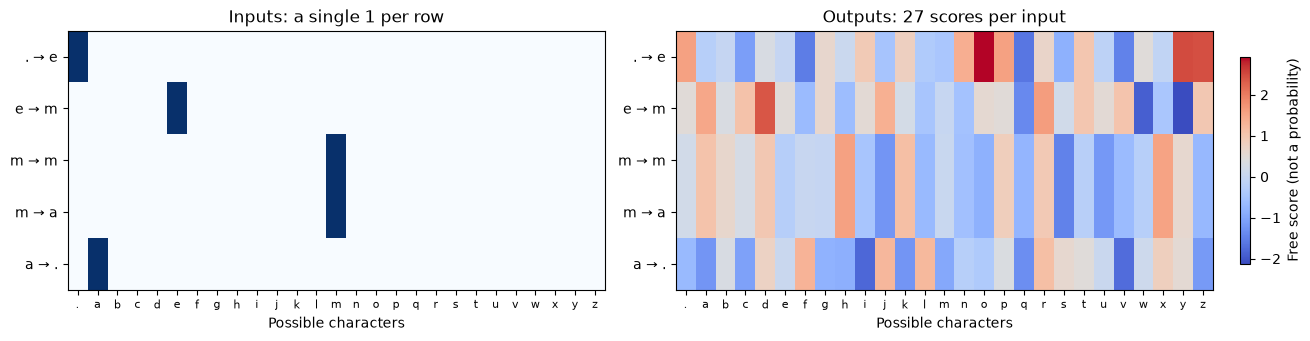

In [6]:
g = torch.Generator().manual_seed(SEED)
W = torch.randn((27, 27), generator=g)

scores_5 = xenc_small @ W
print("xenc_small:", tuple(xenc_small.shape), " @  W:", tuple(W.shape), " =  scores:", tuple(scores_5.shape))
print("one-hot @ W == W[xs_small]?", torch.allclose(scores_5, W[xs_small]))
print("Examples 3 and 4: same input 'm'?", xs_small[2].item() == xs_small[3].item(),
      "| same 27 scores?", torch.allclose(scores_5[2], scores_5[3]))
print("Number of parameters in W:", W.numel(), "= as many as there are cells in N")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.3), constrained_layout=True)
axes[0].imshow(xenc_small.numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
axes[0].set_title("Inputs: a single 1 per row")
im = axes[1].imshow(scores_5.numpy(), cmap="coolwarm", aspect="auto")
axes[1].set_title("Outputs: 27 scores per input")
for ax in axes:
    ax.set_xticks(range(27), [itos[i] for i in range(27)], fontsize=8)
    ax.set_yticks(range(5), [f"{a} → {b}" for a, b in transitions])
    ax.set_xlabel("Possible characters")
fig.colorbar(im, ax=axes[1], label="Free score (not a probability)", shrink=0.8)
plt.show()

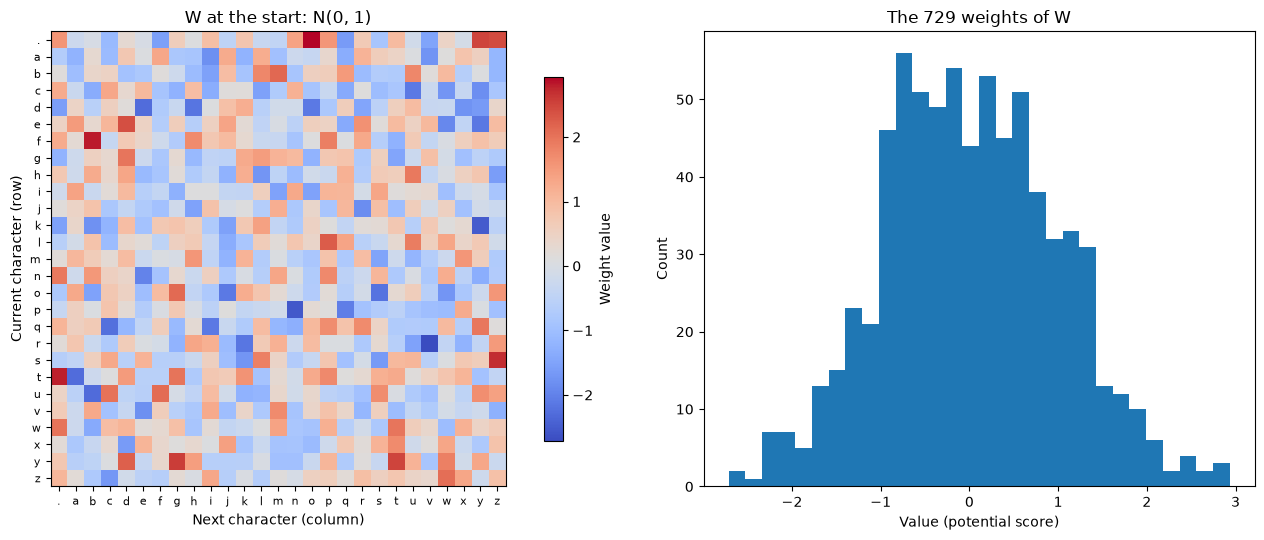

Negative scores are allowed in W: True


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.4, 1]})
plot_char_matrix(W, itos, title="W at the start: N(0, 1)", cbar_label="Weight value",
                 cmap="coolwarm", ax=axes[0])
axes[1].hist(W.flatten().numpy(), bins=30)
axes[1].set(title="The 729 weights of W", xlabel="Value (potential score)", ylabel="Count")
plt.tight_layout(); plt.show()
print("Negative scores are allowed in W:", bool((W < 0).any()))

**Compare with the map of `N` from notebook 01:** here there is no structure at all. `W` knows **nothing** about names. All its knowledge will come from training (notebook 06).

> **Link with chapter 2.** Building a 27-slot one-hot just to read a row is costly. PyTorch provides `nn.Embedding(27, 27)`, which does `W[index]` **directly**. It is exactly the same operation: we will check it in chapter 2.

## 6. The problem that leads to notebook 04

We now know how to **start from a character and get 27 adjustable scores**. But these scores:
- can be **negative**;
- do **not sum to 1**;
- are therefore **not** probabilities;
- and we **cannot** yet apply the NLL from notebook 02 to them, since it needs the probability of the true answer.

**Quick oral check (30 s):** if the current character is `m`, which row of `W` is selected? Why do the two `m`s of `emma` have exactly the same scores? What is missing to compute the loss?

**The question for notebook 04:** how do we turn **any** row of scores into 27 positive probabilities that sum to 1?

## References
- I. Goodfellow, Y. Bengio and A. Courville, [*Deep Learning*](https://www.deeplearningbook.org/), 2016, chapter 6 (*feedforward* networks) and section 15.5 (distributed vs one-hot representations).
- Y. Bengio et al., [*A Neural Probabilistic Language Model*](https://www.jmlr.org/papers/volume3/bengio03a/bengio03a.pdf), JMLR 2003: the first neural language model, which replaces counting with learned parameters.
- Andrej Karpathy, [*The spelled-out intro to language modeling: building makemore*](https://www.youtube.com/watch?v=PaCmpygFfXo) (2022) and the [makemore](https://github.com/karpathy/makemore) repository, where `names.txt` and the spirit of this chapter come from.
- PyTorch documentation: [`F.one_hot`](https://pytorch.org/docs/stable/generated/torch.nn.functional.one_hot.html), [`nn.Embedding`](https://pytorch.org/docs/stable/generated/torch.nn.Embedding.html).